# Room Occupancy Classification with Naive Bayes
## CSE 3207: implementation and experiments
Run all cells from top to bottom. Keep `Occupancy_Estimation.csv` beside this notebook.
Dependencies: Python 3, NumPy, pandas, Matplotlib; Jupyter is needed to open/run the notebook interactively.
No scikit-learn classifier, splitting function, or metric is used.

**Question:** Can environmental sensors distinguish 0, 1, 2 and 3 occupants?
**Extension:** How does performance change between random mixing and transfer between two observed days?
The extension is exploratory; it does not establish future-building performance or a new method.

**Source:** Singh, A. & Chaudhari, S. (2018). Room Occupancy Estimation. UCI Machine Learning Repository.
https://doi.org/10.24432/C5P605 — CC BY 4.0. Original study: Singh et al.,
“Machine Learning-Based Occupancy Estimation Using Multivariate Sensor Nodes,” IEEE Globecom Workshops, 2018.
The repository describes four collection days, but this CSV has seven calendar dates; use the observed dates below.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
CLASSES = np.array([0, 1, 2, 3])
TARGET = 'Room_Occupancy_Count'
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
df = pd.read_csv('Occupancy_Estimation.csv')
timestamp = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%Y/%m/%d %H:%M:%S')
binary = ['S6_PIR', 'S7_PIR']
continuous = [c for c in df.columns if c not in ['Date', 'Time', TARGET] + binary]
features = continuous + binary
X = df[features].to_numpy(dtype=float)
y = df[TARGET].to_numpy(dtype=int)
assert df.isna().sum().sum() == 0
assert np.isfinite(X).all()
assert set(np.unique(y)) == set(CLASSES)
assert np.isin(df[binary].to_numpy(), [0, 1]).all()
print('Rows, raw columns:', df.shape)
print('Continuous features:', len(continuous), '| Binary features:', len(binary))
print('Missing cells:', df.isna().sum().sum(), '| Duplicate full rows:', df.duplicated().sum())
print('Duplicate timestamps:', timestamp.duplicated().sum())
counts = pd.Series(y).value_counts().sort_index()
print(pd.DataFrame({'count': counts, 'percent': (100 * counts / len(y)).round(2)}).to_string())
day_counts = pd.crosstab(timestamp.dt.date, df[TARGET]).reindex(columns=CLASSES, fill_value=0)
day_counts.index.name = 'date'
day_counts.columns.name = 'occupants'
print('\nCounts by date:\n' + day_counts.to_string())
day_counts.to_csv(RESULTS / 'class_counts_by_day.csv')

Rows, raw columns: (10129, 19)
Continuous features: 14 | Binary features: 2
Missing cells: 0 | Duplicate full rows: 0
Duplicate timestamps: 0
   count  percent
0   8228    81.23
1    459     4.53
2    748     7.38
3    694     6.85

Counts by date:
occupants      0    1    2    3
date                           
2017-12-22   637  205  257  363
2017-12-23  1997  254  398  130
2017-12-24  1064    0    0    0
2017-12-25  1716    0    0    0
2017-12-26  1063    0    0    0
2018-01-10   703    0   93  201
2018-01-11  1048    0    0    0


## Inspect the timeline
Each panel shows one date; gaps between dates are not connected. Empty-room observations dominate.
Only December 22 and 23 contain all four classes. A chronological 80/20 split has no class-1
test examples, so it cannot estimate recall for every class. We retain all data for the main
stratified split and use those two complete-class days for the exploratory comparison.

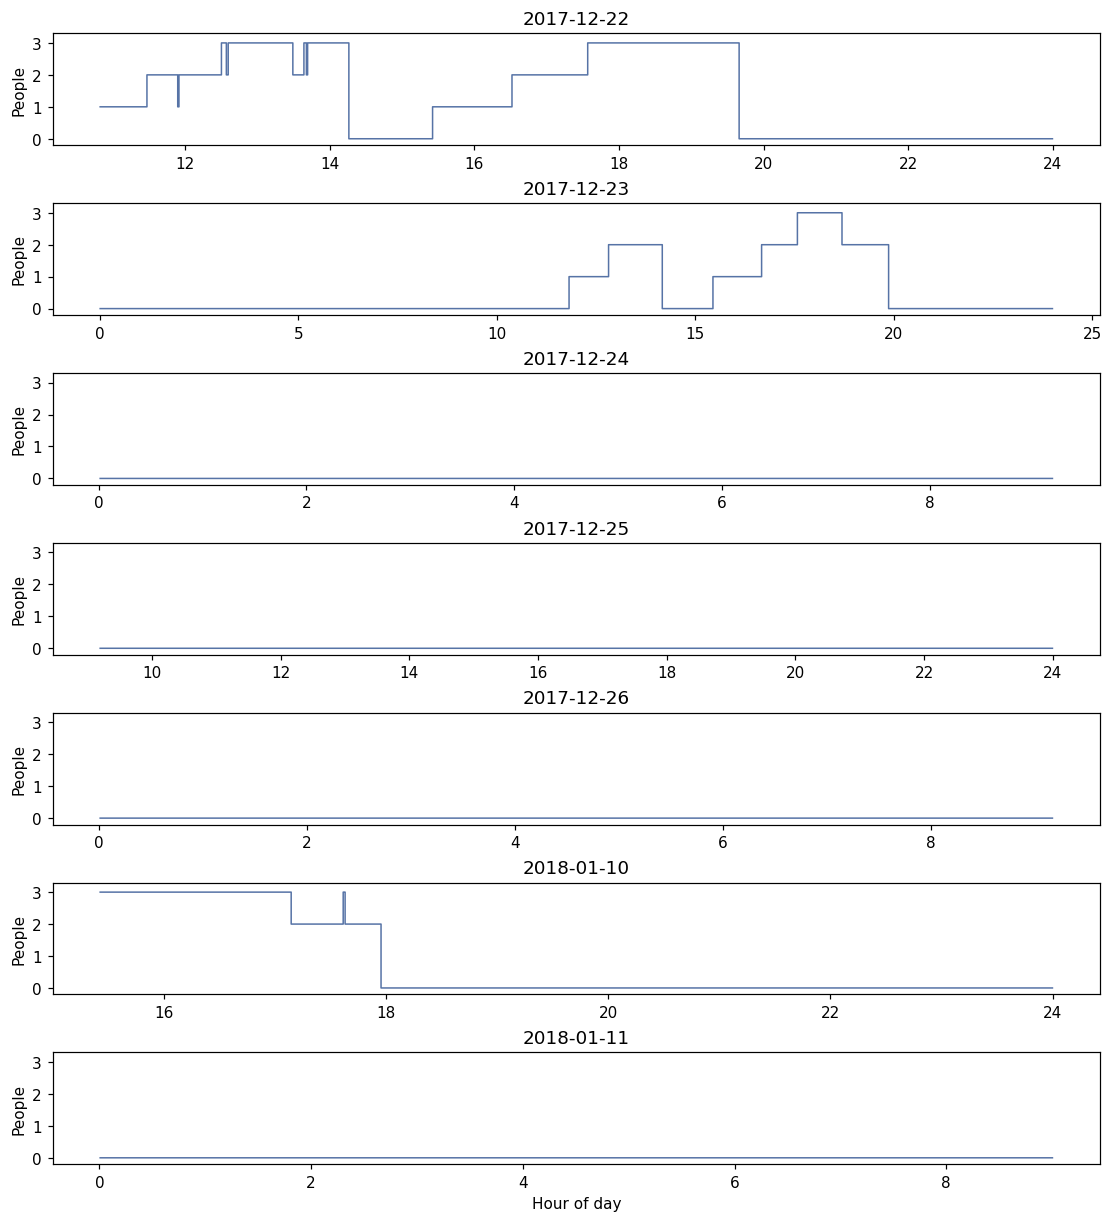

In [2]:
dates = timestamp.dt.strftime('%Y-%m-%d')
unique_dates = sorted(dates.unique())
fig, axes = plt.subplots(len(unique_dates), 1, figsize=(10, 11), constrained_layout=True)
for ax, date in zip(axes, unique_dates):
    mask = dates.eq(date).to_numpy()
    hours = (timestamp[mask] - timestamp[mask].dt.normalize()).dt.total_seconds() / 3600
    ax.step(hours, y[mask], where='post', color='#5673A6', linewidth=1)
    ax.set(title=date, yticks=CLASSES, ylim=(-0.2, 3.3), ylabel='People')
axes[-1].set_xlabel('Hour of day')
fig.savefig(RESULTS / 'occupancy_timeline.png', dpi=160)
plt.show()

## Model from first principles
Bayes' rule gives $P(c\mid x)=P(x\mid c)P(c)/P(x)$.
Under conditional independence, $P(x\mid c)=\prod_j P(x_j\mid c)$.
For prediction, maximize the log score (the common evidence denominator can be omitted):

$$s_c(x)=\log P(c)+\sum_{j\in G}\log\mathcal{N}(x_j;\mu_{cj},\sigma^2_{cj})
+\sum_{j\in B}[x_j\log p_{cj}+(1-x_j)\log(1-p_{cj})].$$

For each class, estimate Gaussian means and population variances from training data only.
Estimate binary motion probabilities with Laplace smoothing:
$p_{cj}=(\text{number of ones}+1)/(n_c+2)$.
Use empirical training priors $P(c)=n_c/n$.
This is a **mixed Gaussian/Bernoulli Naive Bayes**, still one Naive Bayes classifier.
Its Gaussian and conditional-independence assumptions are approximations, not established facts.

For numerical stability, floor each continuous variance at
$10^{-6}\max(\mathrm{Var}_{train}(X_j),10^{-12})$.
This feature-specific floor avoids using the same absolute units for temperature and CO2.
No standardization is necessary; no parameter or preprocessing statistic uses the test data.
Smoothing constants are fixed in advance and are not selected using test scores.

In [3]:
class MixedNaiveBayes:
    """Naive Bayes with Gaussian continuous features and Bernoulli binary features.

    Input columns must place continuous features before binary features.
    """
    def __init__(self, n_continuous, alpha=1.0, variance_floor=1e-6):
        self.n_continuous = n_continuous
        self.alpha = alpha
        self.variance_floor = variance_floor

    def fit(self, X, y):
        """Estimate priors and class-conditional parameters from training rows only."""
        self.classes_ = np.unique(y)
        g = X[:, :self.n_continuous]
        # A feature-specific variance floor prevents division by zero in each sensor's units.
        floor = self.variance_floor * np.maximum(g.var(axis=0), 1e-12)
        self.log_prior_, self.mean_, self.var_, self.prob_ = [], [], [], []
        for c in self.classes_:
            # Each class has its own prior, Gaussian means/variances and PIR probabilities.
            rows = X[y == c]
            self.log_prior_.append(np.log(len(rows) / len(X)))
            self.mean_.append(rows[:, :self.n_continuous].mean(axis=0))
            self.var_.append(np.maximum(rows[:, :self.n_continuous].var(axis=0), floor))
            # Laplace smoothing keeps Bernoulli probabilities strictly between zero and one.
            ones = rows[:, self.n_continuous:].sum(axis=0)
            self.prob_.append((ones + self.alpha) / (len(rows) + 2 * self.alpha))
        # Arrays have one row per class and one column per corresponding feature.
        self.log_prior_, self.mean_, self.var_, self.prob_ = map(
            np.asarray, [self.log_prior_, self.mean_, self.var_, self.prob_])
        return self

    def log_scores(self, X):
        """Return unnormalized log class scores, shape (n_samples, n_classes)."""
        g, b = X[:, :self.n_continuous], X[:, self.n_continuous:]
        scores = []
        for k in range(len(self.classes_)):
            # Log Gaussian density is computed independently for every continuous feature.
            gaussian = -0.5 * (np.log(2 * np.pi * self.var_[k])
                              + (g - self.mean_[k]) ** 2 / self.var_[k])
            # Binary features contribute log(p) for one and log(1-p) for zero.
            bernoulli = b * np.log(self.prob_[k]) + (1 - b) * np.log1p(-self.prob_[k])
            # Conditional independence makes likelihood products become sums in log space.
            scores.append(self.log_prior_[k] + gaussian.sum(axis=1) + bernoulli.sum(axis=1))
        return np.column_stack(scores)

    def predict(self, X):
        """Return the original class label with the largest log score for each row."""
        # Map score-column indices back to labels rather than assuming labels equal indices.
        return self.classes_[np.argmax(self.log_scores(X), axis=1)]

    def predict_proba(self, X):
        """Normalize class scores; these probabilities are not assumed calibrated."""
        scores = self.log_scores(X)
        # Subtracting each row maximum preserves ratios while preventing overflow.
        weights = np.exp(scores - scores.max(axis=1, keepdims=True))
        # Each output row sums to one.
        return weights / weights.sum(axis=1, keepdims=True)

## Splitting and evaluation from scratch
Shuffle indices within each class and hold out approximately 20% of each class using a fixed seed.
Confusion-matrix rows are actual labels; columns are predictions.
For class $c$: precision $=TP/(TP+FP)$, recall $=TP/(TP+FN)$,
and $F1=2PR/(P+R)$. A zero denominator is reported as zero.
Macro averages give each of the four classes equal weight; weighted F1 weights by test support.
The majority baseline predicts the most frequent **training** class.

In [4]:
def stratified_split(y, test_fraction=0.2, seed=SEED):
    """Return reproducible, disjoint row indices with each class represented on both sides."""
    rng = np.random.default_rng(seed)
    train, test = [], []
    for c in np.unique(y):
        # Shuffle within each class so its approximate proportion is retained.
        indices = np.flatnonzero(y == c)
        rng.shuffle(indices)
        # Round upward for the test count, reserving at least one training row.
        n_test = min(len(indices) - 1, max(1, int(np.ceil(test_fraction * len(indices)))))
        test.extend(indices[:n_test])
        train.extend(indices[n_test:])
    return rng.permutation(train), rng.permutation(test)

def evaluate(actual, predicted):
    """Compute four-class metrics; confusion rows are actual and columns predicted.

    The fixed labels are 0, 1, 2, 3. Undefined class ratios are reported as zero.
    """
    cm = np.zeros((4, 4), dtype=int)
    # Accumulate one observation at the intersection of its true and predicted labels.
    np.add.at(cm, (actual, predicted), 1)
    tp = np.diag(cm).astype(float)
    support = cm.sum(axis=1)
    predicted_count = cm.sum(axis=0)
    # Safe division avoids NaNs for a class receiving no predictions.
    precision = np.divide(tp, predicted_count, out=np.zeros(4), where=predicted_count != 0)
    recall = np.divide(tp, support, out=np.zeros(4), where=support != 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros(4), where=(precision + recall) != 0)
    table = pd.DataFrame({'precision': precision, 'recall': recall, 'f1': f1,
                          'support': support}, index=pd.Index(CLASSES, name='occupants'))
    # Macro metrics weight classes equally; weighted F1 uses actual test support.
    metrics = {'accuracy': tp.sum() / cm.sum(), 'macro_precision': precision.mean(),
               'macro_recall': recall.mean(), 'macro_f1': f1.mean(),
               'weighted_f1': np.sum(f1 * support) / support.sum()}
    return metrics, table, cm

def run_case(name, train, test):
    """Fit a fresh model, evaluate a fixed partition, and save reproducible outputs."""
    # Prevent train/test overlap and ensure every class can be evaluated.
    assert not np.intersect1d(train, test).size
    assert set(y[train]) == set(CLASSES) and set(y[test]) == set(CLASSES)
    # Test data are passed only to prediction; no parameters are fitted on them.
    model = MixedNaiveBayes(len(continuous)).fit(X[train], y[train])
    pred = model.predict(X[test])
    probabilities = model.predict_proba(X[test])
    assert np.isfinite(probabilities).all() and np.allclose(probabilities.sum(axis=1), 1)
    metrics, table, cm = evaluate(y[test], pred)
    # The baseline chooses its constant class from training labels only.
    majority = np.bincount(y[train], minlength=4).argmax()
    baseline, _, _ = evaluate(y[test], np.full(len(test), majority))
    row = dict(experiment=name, n_train=len(train), n_test=len(test), **metrics,
               baseline_accuracy=baseline['accuracy'], baseline_macro_f1=baseline['macro_f1'])
    # Save class metrics, predictions and indices so the experiment can be traced.
    table.to_csv(RESULTS / (name + '_per_class.csv'))
    pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(RESULTS / (name + '_confusion.csv'))
    pd.DataFrame({'row_index': test, 'actual': y[test], 'predicted': pred}).to_csv(
        RESULTS / (name + '_predictions.csv'), index=False)
    pd.DataFrame({'row_index': train}).to_csv(RESULTS / (name + '_train_indices.csv'), index=False)
    return row, model, pred, table, cm

train, test = stratified_split(y)
main, main_model, main_pred, main_table, main_cm = run_case('main_random_80_20', train, test)
print(pd.Series(main).to_string())
print('\nPer-class results:\n' + main_table.round(4).to_string())

experiment           main_random_80_20
n_train                           8102
n_test                            2027
accuracy                      0.952639
macro_precision               0.870951
macro_recall                  0.908494
macro_f1                      0.888188
weighted_f1                   0.954224
baseline_accuracy             0.812037
baseline_macro_f1             0.224068

Per-class results:
           precision  recall      f1  support
occupants                                    
0             0.9907  0.9696  0.9800     1646
1             1.0000  0.9783  0.9890       92
2             0.8480  0.9667  0.9034      150
3             0.6452  0.7194  0.6803      139


## Required visualizations
The label-distribution plot compares counts on the same test set; matching distributions alone
does not establish correct individual predictions. Use it alongside the confusion matrix.

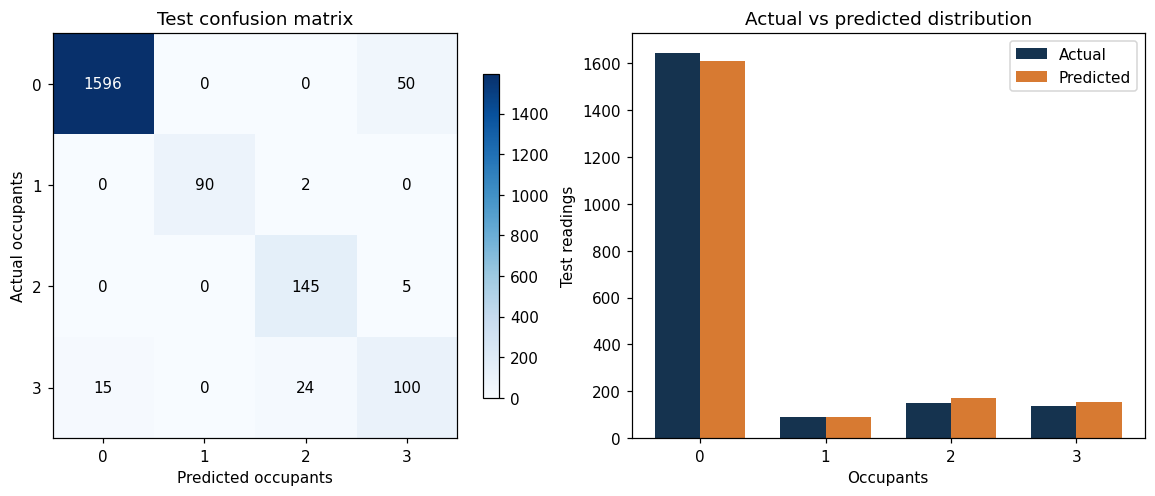

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
im = axes[0].imshow(main_cm, cmap='Blues')
for i in range(4):
    for j in range(4):
        axes[0].text(j, i, str(main_cm[i, j]), ha='center', va='center',
                     color='white' if main_cm[i, j] > main_cm.max()/2 else 'black')
axes[0].set(xticks=CLASSES, yticks=CLASSES, xlabel='Predicted occupants',
            ylabel='Actual occupants', title='Test confusion matrix')
fig.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].bar(CLASSES - .18, np.bincount(y[test], minlength=4), .36, label='Actual', color='#15334F')
axes[1].bar(CLASSES + .18, np.bincount(main_pred, minlength=4), .36, label='Predicted', color='#D77A32')
axes[1].set(xticks=CLASSES, xlabel='Occupants', ylabel='Test readings', title='Actual vs predicted distribution')
axes[1].legend()
fig.savefig(RESULTS / 'main_evaluation.png', dpi=180)
plt.show()

## Exploratory cross-day experiment with matched random controls
Use December 22 and December 23 only, because both include every class.
For each transfer direction, a random control pools these **same two days** and preserves
the cross-day training/test class counts exactly. Repeat random allocation for five fixed seeds.
Thus sample size, class proportions, and the source-day pool are matched; the cross-day model
must still face a different day's sensor conditions. Never tune the model on either test set.

This control improves comparability over comparing cross-day results only with the full-data 80/20 split.
The two transfer directions are exploratory reuse of the data, not independent confirmation tests.
A drop may reflect changing sensor distributions, temporal dependence, or both; it does not isolate
one causal explanation. Reverse transfer is not a simulation of forecasting the future.

In [6]:
first = np.flatnonzero(dates.eq('2017-12-22').to_numpy())
second = np.flatnonzero(dates.eq('2017-12-23').to_numpy())
pool = np.concatenate([first, second])
rows = [main]
for label, transfer_train, transfer_test in [('22_to_23', first, second), ('23_to_22', second, first)]:
    row, *_ = run_case('cross_day_' + label, transfer_train, transfer_test)
    rows.append(row)
    for seed in [42, 43, 44, 45, 46]:
        rng = np.random.default_rng(seed)
        matched_train, matched_test = [], []
        for c in CLASSES:
            candidates = rng.permutation(pool[y[pool] == c])
            n_train = int(np.sum(y[transfer_train] == c))
            matched_train.extend(candidates[:n_train])
            matched_test.extend(candidates[n_train:])
        row, *_ = run_case('matched_random_' + label + '_seed_' + str(seed),
                           np.array(matched_train), np.array(matched_test))
        rows.append(row)
summary = pd.DataFrame(rows)
summary.to_csv(RESULTS / 'experiment_summary.csv', index=False)
print(summary[['experiment', 'n_train', 'n_test', 'accuracy', 'macro_f1']].round(4).to_string(index=False))

                     experiment  n_train  n_test  accuracy  macro_f1
              main_random_80_20     8102    2027    0.9526    0.8882
             cross_day_22_to_23     1462    2779    0.9921    0.9839
matched_random_22_to_23_seed_42     1462    2779    0.9816    0.9554
matched_random_22_to_23_seed_43     1462    2779    0.9842    0.9656
matched_random_22_to_23_seed_44     1462    2779    0.9763    0.9548
matched_random_22_to_23_seed_45     1462    2779    0.9827    0.9624
matched_random_22_to_23_seed_46     1462    2779    0.9842    0.9662
             cross_day_23_to_22     2779    1462    0.7004    0.6127
matched_random_23_to_22_seed_42     2779    1462    0.9713    0.9625
matched_random_23_to_22_seed_43     2779    1462    0.9815    0.9757
matched_random_23_to_22_seed_44     2779    1462    0.9726    0.9649
matched_random_23_to_22_seed_45     2779    1462    0.9706    0.9621
matched_random_23_to_22_seed_46     2779    1462    0.9802    0.9745


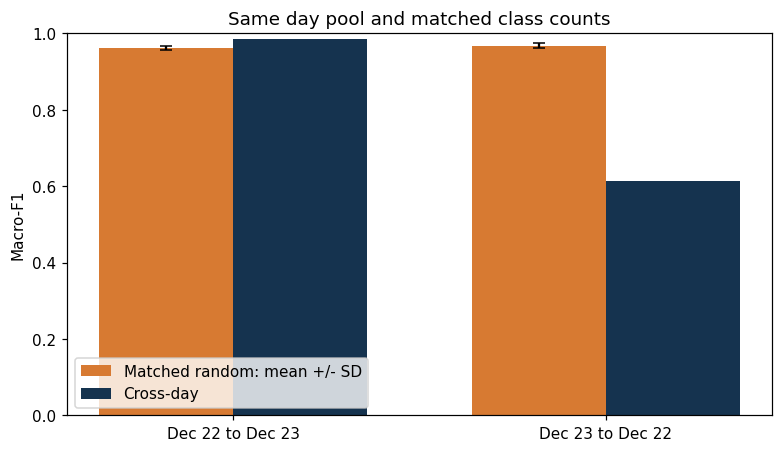

direction  cross_day_accuracy  random_accuracy_mean  cross_day_macro_f1  random_macro_f1_mean  random_macro_f1_sd
 22_to_23              0.9921                0.9818              0.9839                0.9609              0.0055
 23_to_22              0.7004                0.9752              0.6127                0.9679              0.0066


In [7]:
comparison = []
for direction in ['22_to_23', '23_to_22']:
    transfer = summary.loc[summary.experiment.eq('cross_day_' + direction)].iloc[0]
    controls = summary.loc[summary.experiment.str.startswith('matched_random_' + direction)]
    comparison.append({'direction': direction, 'cross_day_accuracy': transfer.accuracy,
        'random_accuracy_mean': controls.accuracy.mean(),
        'cross_day_macro_f1': transfer.macro_f1,
        'random_macro_f1_mean': controls.macro_f1.mean(),
        'random_macro_f1_sd': controls.macro_f1.std(ddof=1)})
comparison = pd.DataFrame(comparison)
comparison.to_csv(RESULTS / 'cross_day_comparison.csv', index=False)
print(comparison.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
p = np.arange(2)
ax.bar(p-.18, comparison.random_macro_f1_mean, .36,
       yerr=comparison.random_macro_f1_sd, capsize=4, color='#D77A32', label='Matched random: mean +/- SD')
ax.bar(p+.18, comparison.cross_day_macro_f1, .36, color='#15334F', label='Cross-day')
ax.set(xticks=p, xticklabels=['Dec 22 to Dec 23', 'Dec 23 to Dec 22'],
       ylabel='Macro-F1', ylim=(0, 1), title='Same day pool and matched class counts')
ax.legend(loc='lower left')
fig.savefig(RESULTS / 'cross_day_comparison.png', dpi=180)
plt.show()

## Extra experiment: which sensor groups carry useful information?
Compare all sensors with each of five predefined sensor groups. Keep exactly the same
training/test indices, empirical priors, smoothing and metric definitions as the main 80/20
evaluation. Numerical groups use Gaussian likelihoods; motion-only uses Bernoulli likelihoods.
CO2 includes both its level and supplied slope, so it represents two derived inputs from one
sensor stream. Temperature, light and sound each include four sensor locations.

These are **group-only comparisons**, not leave-one-group-out ablations: they show what each
group can do alone, not its unique contribution after controlling for the other groups.
Feature counts differ between groups. This is an exploratory comparison on an already-used
test set, not a procedure for selecting a deployment model or tuning features on test scores.

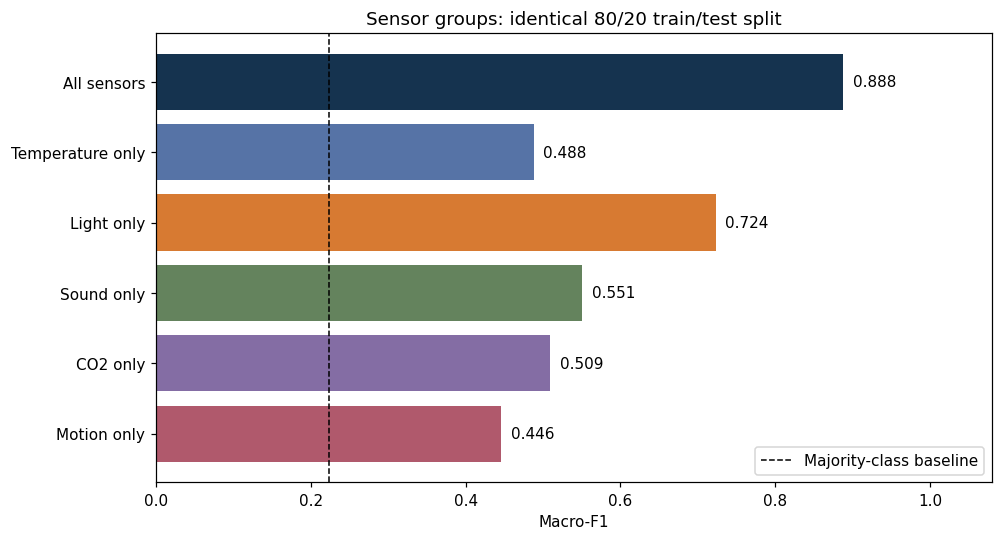

                  n_features  accuracy  macro_f1
sensor_group                                    
All sensors               16    0.9526    0.8882
Temperature only           4    0.8268    0.4879
Light only                 4    0.9008    0.7235
Sound only                 4    0.8816    0.5510
CO2 only                   2    0.8495    0.5095
Motion only                2    0.8678    0.4463

Recall by actual occupancy class:
                  recall_0_occupants  recall_1_occupants  recall_2_occupants  recall_3_occupants
All sensors                   0.9696              0.9783              0.9667              0.7194
Temperature only              0.9101              0.0000              0.5667              0.6691
Light only                    0.9526              1.0000              0.9933              0.1223
Sound only                    0.9970              0.5217              0.5200              0.1439
CO2 only                      0.9465              0.0000              0.5400            

In [8]:
groups = {
    'All sensors': features,
    'Temperature only': [c for c in continuous if c.endswith('_Temp')],
    'Light only': [c for c in continuous if c.endswith('_Light')],
    'Sound only': [c for c in continuous if c.endswith('_Sound')],
    'CO2 only': ['S5_CO2', 'S5_CO2_Slope'],
    'Motion only': binary,
}
sensor_rows, sensor_recalls, sensor_predictions = [], [], {'row_index': test, 'actual': y[test]}
for name, columns in groups.items():
    continuous_columns = [c for c in columns if c in continuous]
    binary_columns = [c for c in columns if c in binary]
    ordered_columns = continuous_columns + binary_columns
    group_X = df[ordered_columns].to_numpy(dtype=float)
    model = MixedNaiveBayes(len(continuous_columns)).fit(group_X[train], y[train])
    predicted = model.predict(group_X[test])
    probabilities = model.predict_proba(group_X[test])
    assert np.isfinite(probabilities).all() and np.allclose(probabilities.sum(axis=1), 1)
    metrics, table, cm = evaluate(y[test], predicted)
    if name == 'All sensors':
        assert np.array_equal(predicted, main_pred)
    sensor_rows.append({'sensor_group': name, 'n_features': len(columns), **metrics})
    sensor_recalls.append(table['recall'].rename(name))
    slug = name.lower().replace(' ', '_')
    table.to_csv(RESULTS / ('sensors_' + slug + '_per_class.csv'))
    pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(
        RESULTS / ('sensors_' + slug + '_confusion.csv'))
    sensor_predictions[name] = predicted

sensor_summary = pd.DataFrame(sensor_rows).set_index('sensor_group')
sensor_recall = pd.DataFrame(sensor_recalls)
sensor_recall.columns = ['recall_' + str(c) + '_occupants' for c in CLASSES]
sensor_summary.join(sensor_recall).to_csv(RESULTS / 'sensor_group_comparison.csv')
pd.DataFrame(sensor_predictions).to_csv(RESULTS / 'sensor_group_predictions.csv', index=False)
print(sensor_summary[['n_features', 'accuracy', 'macro_f1']].round(4).to_string())
print('\nRecall by actual occupancy class:\n' + sensor_recall.round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 4.8), constrained_layout=True)
positions = np.arange(len(sensor_summary))
bars = ax.barh(positions, sensor_summary.macro_f1, color=['#15334F', '#5673A6', '#D77A32', '#64835D', '#846DA4', '#B0596C'])
ax.set(yticks=positions, yticklabels=sensor_summary.index, xlim=(0, 1.08),
       xlabel='Macro-F1', title='Sensor groups: identical 80/20 train/test split')
ax.invert_yaxis()
for bar, score in zip(bars, sensor_summary.macro_f1):
    ax.text(score + .012, bar.get_y() + bar.get_height()/2, f'{score:.3f}', va='center')
ax.axvline(main['baseline_macro_f1'], color='black', linestyle='--', linewidth=1,
           label='Majority-class baseline')
ax.legend(loc='lower right')
fig.savefig(RESULTS / 'sensor_group_comparison.png', dpi=180)
plt.show()

Read the comparison together with the per-class recalls: a group can classify empty rooms
reasonably while failing to distinguish occupied counts. More inputs need not improve Naive
Bayes, since additional likelihood terms can be poorly modelled or redundant. A group doing
well here does not establish hardware cost savings or performance in new rooms. The identical
random split makes groups comparable on this test set, but retains the temporal-dependence
limitations discussed above. Cross-day transfer of these sensor subsets is not evaluated here.

## Sanity checks and interpretation
These checks confirm metric orientation on a known example, partition completeness,
and agreement between vectorized scores and a scalar likelihood calculation.
They do not establish that the statistical assumptions are true.

In [9]:
known, _, cm_known = evaluate(np.array([0, 0, 1, 2, 3]), np.array([0, 1, 1, 2, 3]))
assert known['accuracy'] == 0.8 and cm_known[0, 1] == 1
assert len(train) + len(test) == len(y)
assert len(np.unique(np.concatenate([train, test]))) == len(y)
x = X[test[0]]
manual = []
for k in range(4):
    value = main_model.log_prior_[k]
    for j in range(len(continuous)):
        v = main_model.var_[k, j]
        value += -.5 * (np.log(2*np.pi*v) + (x[j]-main_model.mean_[k,j])**2/v)
    for j in range(len(binary)):
        p = main_model.prob_[k, j]
        value += np.log(p if x[len(continuous)+j] else 1-p)
    manual.append(value)
assert np.allclose(manual, main_model.log_scores(x[None, :])[0])
print('All numerical and partition checks passed.')
print('\nMain accuracy: {:.2%}; majority baseline: {:.2%}; macro-F1: {:.4f}'.format(
    main['accuracy'], main['baseline_accuracy'], main['macro_f1']))
for _, r in comparison.iterrows():
    print('{}: matched random macro-F1 {:.4f} +/- {:.4f}; cross-day {:.4f}'.format(
        r.direction, r.random_macro_f1_mean, r.random_macro_f1_sd, r.cross_day_macro_f1))
print('\nPackage versions:', 'NumPy', np.__version__, 'pandas', pd.__version__)

All numerical and partition checks passed.

Main accuracy: 95.26%; majority baseline: 81.20%; macro-F1: 0.8882
22_to_23: matched random macro-F1 0.9609 +/- 0.0055; cross-day 0.9839
23_to_22: matched random macro-F1 0.9679 +/- 0.0066; cross-day 0.6127

Package versions: NumPy 2.3.5 pandas 2.2.3


## Findings and limitations

The full model reaches **95.26% accuracy** and **0.8882 macro-F1** on the fixed
stratified test split, exceeding the majority baseline of **81.20% accuracy**.
Three-occupant readings have lower recall (71.94%) than the other classes.
Light alone has the highest macro-F1 among individual sensor groups, but its
three-occupant recall is only 12.23%. These class-wise differences explain why
accuracy is insufficient for this imbalanced task.

Transfer between December 22 and 23 is directional: macro-F1 is 0.9839 in the
forward direction and 0.6127 in reverse. The matched random controls do not
support a claim that every cross-day split must perform worse. The five-seed
standard deviations describe random allocation variability, not uncertainty
across independent rooms.

The data come from one controlled room, with temporally dependent readings.
Conditional independence and Gaussian likelihoods are approximations; normalized
probabilities are not demonstrated to be calibrated. The causal construction of
the supplied CO2 slope was not independently verified. Sensor-group results are
exploratory comparisons on the same test set, not deployment recommendations.
Generalization to other rooms, hardware cost savings and online readiness are
outside this experiment's evidence.
